In [38]:
import pandas as pd
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np



## Carga y visualización inicial de las imágenes

Las imágenes se encuentran organizadas en subcarpetas dentro de `Data`,
según su diagnóstico: carcinoma basocelular (BCC), carcinoma escamoso
(SCC) y queratosis seborreica (SK).

Se carga y visualiza una imagen de cada grupo para inspeccionar sus
características y detectar elementos que puedan afectar el procesamiento.
Las imágenes se convierten de BGR a RGB para representar correctamente
sus colores.

En esta etapa se conserva la resolución original y no se aplican filtros.

BCC: 22 imágenes
SCC: 16 imágenes
SK: 21 imágenes


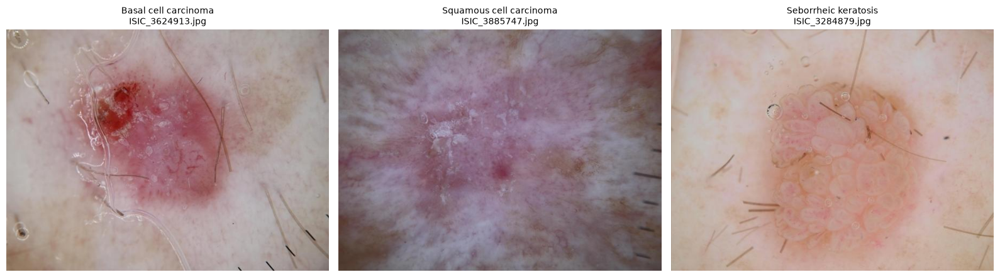

In [53]:
carpeta_data = Path("Data")

grupos = {
    "BCC": "Basal cell carcinoma",
    "SCC": "Squamous cell carcinoma",
    "SK": "Seborrheic keratosis",
}

imagenes = {}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (carpeta, diagnostico) in zip(axes, grupos.items()):
    archivos = sorted(
        p for p in (carpeta_data / carpeta).rglob("*")
    )

    if not archivos:
        raise FileNotFoundError(f"No hay imágenes en {carpeta}")

    ruta = archivos[6] if len(archivos) > 1 else archivos[0]
    imagen = cv2.imread(str(ruta))

    if imagen is None:
        raise ValueError(f"No se pudo leer: {ruta}")

    imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    # Guardar la imagen para el preprocesamiento
    imagenes[carpeta] = imagen_rgb

    ax.imshow(imagen_rgb)
    ax.set_title(f"{diagnostico}\n{ruta.name}", fontsize=10)
    ax.axis("off")

    print(f"{carpeta}: {len(archivos)} imágenes")

plt.tight_layout()
plt.show()

### Observaciones iniciales

En los ejemplos seleccionados se observan diferencias de color, contraste
y apariencia superficial. La imagen BCC presenta una región rosada de
bajo contraste respecto de la piel circundante. En la imagen SCC se
observan numerosos pelos y estructuras circulares compatibles con
burbujas. La imagen SK presenta una región de pigmentación heterogénea.
También se identifican marcas de escala en algunas imágenes.

Estos elementos pueden interferir en la segmentación y modificar las
mediciones de color y textura. Por ello, se evaluarán técnicas de
preprocesamiento procurando preservar los detalles de la lesión.

Estas observaciones corresponden únicamente a las imágenes mostradas
y no se consideran características generales de cada diagnóstico.

## Preprocesamiento: comparación de filtros de suavizado

Se comparan un filtro de mediana y un filtro gaussiano, utilizando
ventanas de 3 × 3 píxeles.

El filtro de mediana reemplaza cada valor por la mediana de su entorno.
El filtro gaussiano realiza un promedio ponderado, asignando mayor peso
a los píxeles cercanos al centro de la ventana.

Se aplica cada filtro de manera independiente sobre la imagen original.
Se evalúa visualmente su efecto sobre los bordes y los detalles de la
lesión. No se asume que las imágenes presentan ruido de un tipo específico
ni que el suavizado mejora necesariamente su calidad.

Estos filtros no constituyen un método específico de eliminación de pelos.

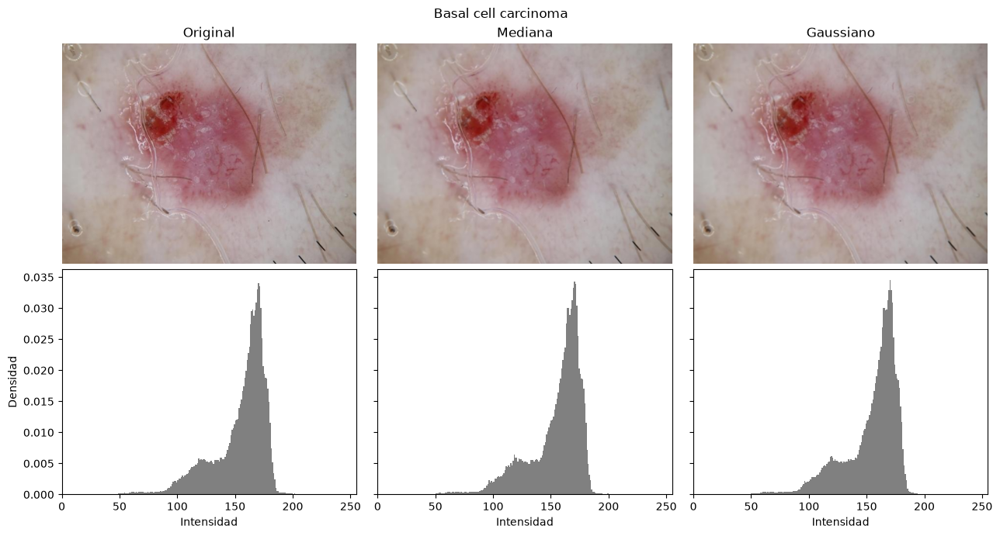

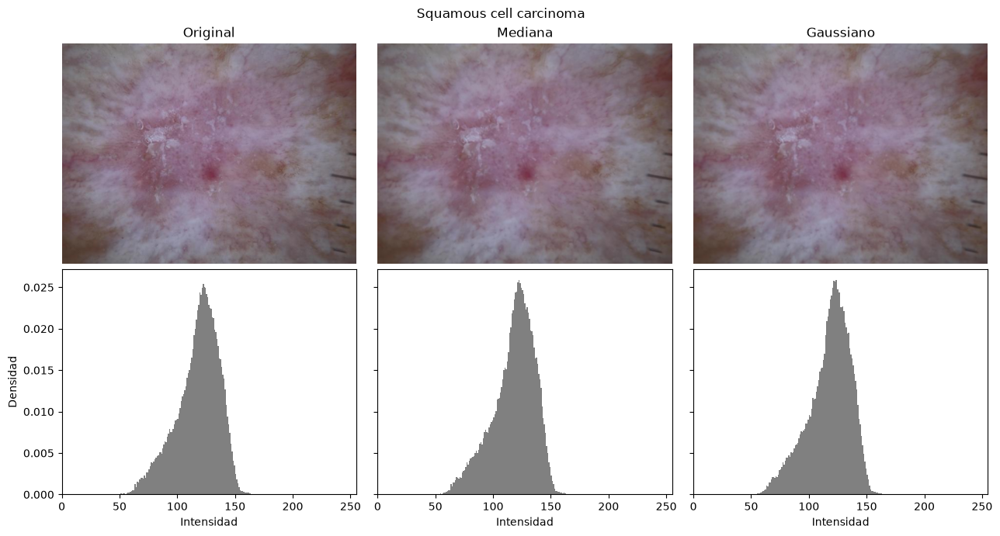

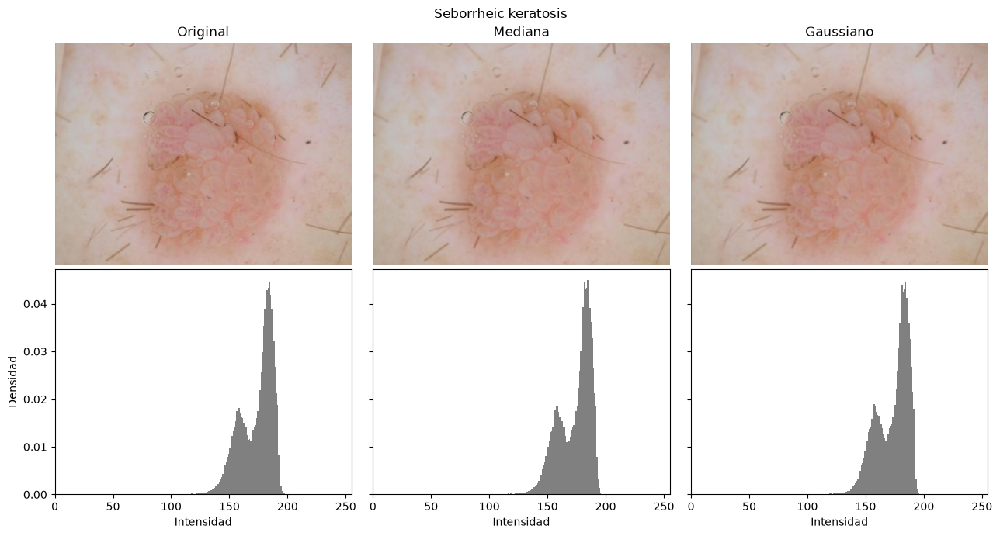

In [54]:
for tipo, original in imagenes.items():

    variantes = {
        "Original": original,
        "Mediana": cv2.medianBlur(original, 3),
        "Gaussiano": cv2.GaussianBlur(original, (3, 3), 1),
    }

    fig, axes = plt.subplots(
        2, 3, figsize=(13, 7),
        sharex="row", sharey="row"
    )
    fig.suptitle(grupos[tipo])

    for columna, (nombre, imagen) in enumerate(variantes.items()):
        # Mostrar imagen
        axes[0, columna].imshow(imagen)
        axes[0, columna].set_title(nombre)
        axes[0, columna].axis("off")

        # Mostrar histograma en escala de grises
        gris = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)

        axes[1, columna].hist(
            gris.ravel(),
            bins=256,
            range=(0, 256),
            density=True,
            color="gray"
        )
        axes[1, columna].set_xlabel("Intensidad")
        axes[1, columna].set_xlim(0, 255)

    axes[1, 0].set_ylabel("Densidad")

    plt.tight_layout()
    plt.show()

### Resultado de la comparación

En el ejemplo de carcinoma basocelular, los filtros de mediana y
gaussiano con ventanas de 3 × 3 producen cambios visuales sutiles.
Los histogramas mantienen una distribución similar a la original.

La similitud entre histogramas no implica que se conserven todos los
detalles espaciales. Por ello, se requiere inspeccionar regiones ampliadas
y evaluar posteriormente el efecto sobre la segmentación.

Los pelos y las marcas de escala permanecen visibles tras el filtrado.

## Pruebas de mejora de contraste

Se comparan dos métodos de mejora de contraste: ecualización global del
histograma y ecualización adaptativa con limitación de contraste (CLAHE).

Ambos métodos se aplican sobre las versiones en escala de grises de las
tres imágenes seleccionadas, utilizando los mismos parámetros para todos
los diagnósticos. Se visualizan los resultados y sus histogramas para
evaluar los cambios en la distribución de intensidades y el realce de
detalles y artefactos.

El objetivo es identificar una alternativa que facilite la segmentación
posterior, procurando preservar las características relevantes de las
lesiones.

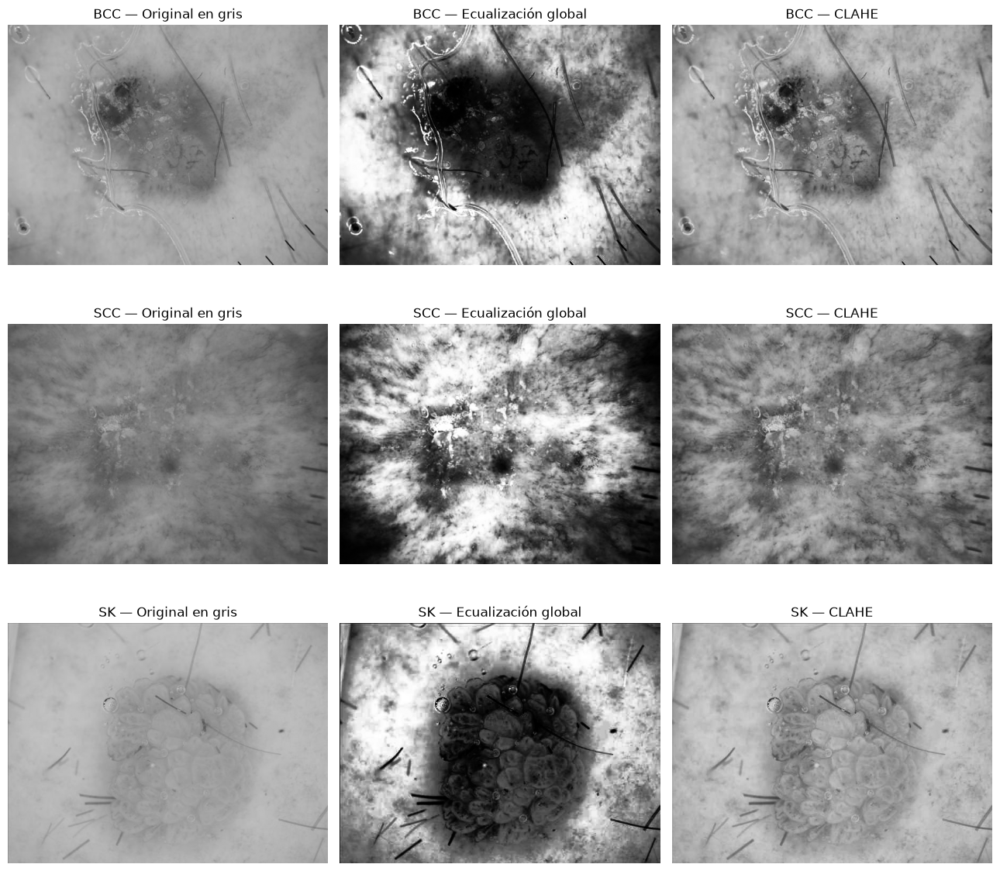

In [55]:
contraste = {}

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

fig, axes = plt.subplots(3, 3, figsize=(13, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    variantes = {
        "Original en gris": gris,
        "Ecualización global": cv2.equalizeHist(gris),
        "CLAHE": clahe.apply(gris),
    }

    contraste[tipo] = variantes

    for columna, (nombre, imagen) in enumerate(variantes.items()):
        axes[fila, columna].imshow(
            imagen, cmap="gray", vmin=0, vmax=255
        )
        axes[fila, columna].set_title(f"{tipo} — {nombre}")
        axes[fila, columna].axis("off")

plt.tight_layout()
plt.show()

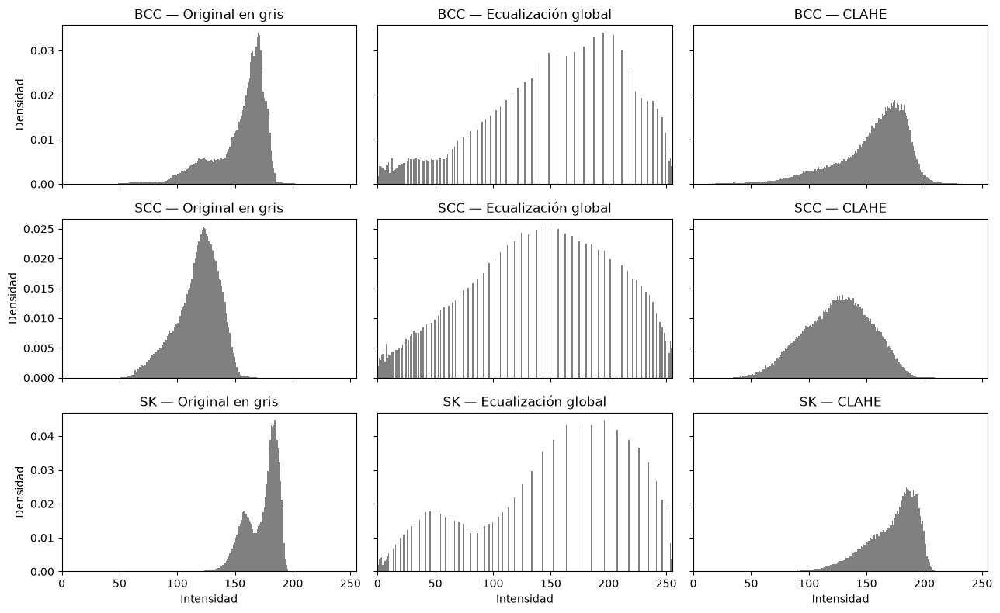

In [56]:
fig, axes = plt.subplots(
    3, 3, figsize=(13, 8),
    sharex=True, sharey="row"
)

for fila, (tipo, variantes) in enumerate(contraste.items()):
    for columna, (nombre, imagen) in enumerate(variantes.items()):
        ax = axes[fila, columna]

        ax.hist(
            imagen.ravel(), bins=256,
            range=(0, 256), density=True, color="gray"
        )
        ax.set_title(f"{tipo} — {nombre}")
        ax.set_xlim(0, 255)

        if fila == 2:
            ax.set_xlabel("Intensidad")
        if columna == 0:
            ax.set_ylabel("Densidad")

plt.tight_layout()
plt.show()

### Comparación de los métodos de mejora de contraste

En los tres ejemplos, la ecualización global amplía el rango de
intensidades y produce un aumento pronunciado del contraste. Sin embargo,
también realza estructuras de la piel circundante y artefactos que podrían
interferir en la segmentación.

CLAHE produce un realce visual más moderado con los parámetros utilizados.
Por ello, se selecciona como alternativa preliminar para continuar el
desarrollo del pipeline, manteniendo los mismos parámetros para los tres
diagnósticos.

Esta selección deberá validarse mediante la segmentación y su evaluación
sobre más imágenes. La ampliación del histograma, por sí sola, no demuestra
una mejora en la delimitación de las lesiones.

## Detección de posibles pelos y artefactos oscuros

Se aplica la transformación morfológica black-hat, calculada como la
diferencia entre el cierre de la imagen y la imagen original. Esta
operación resalta estructuras oscuras menores que el elemento
estructurante utilizado.

La respuesta se umbraliza para obtener una máscara de posibles
artefactos. Se utilizan los mismos parámetros para las tres imágenes.

Se inspecciona la máscara antes de corregir los píxeles detectados,
ya que también pueden incluirse marcas de escala y estructuras propias
de la lesión.

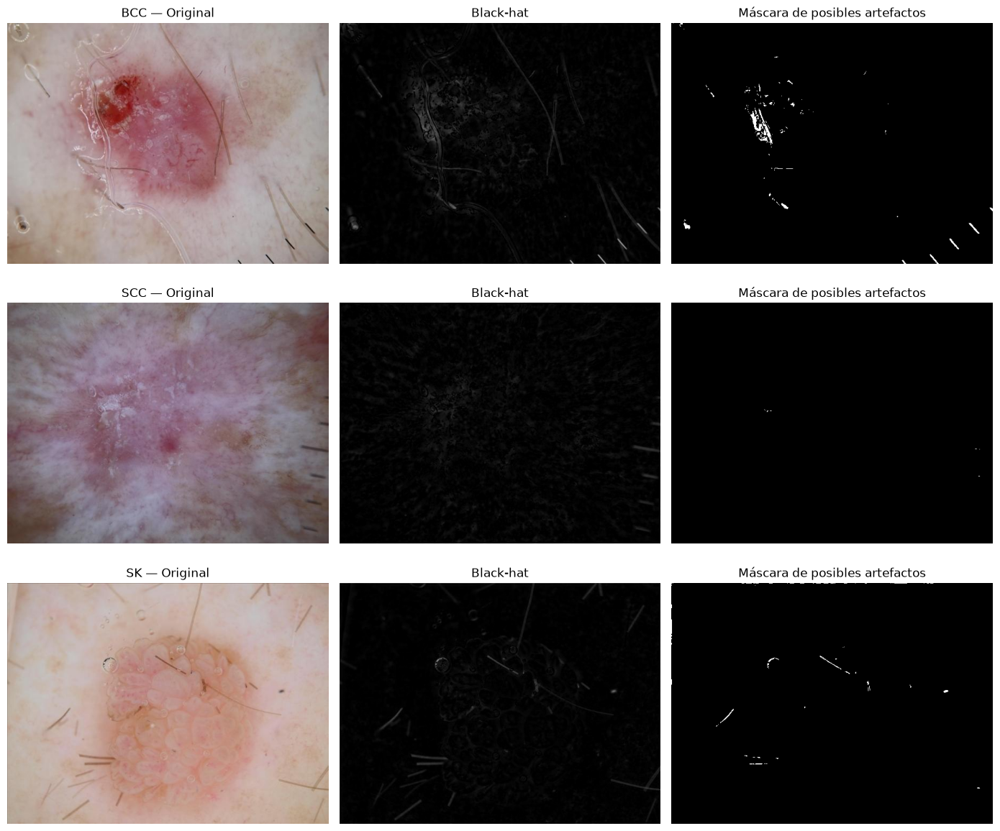

In [68]:
mascaras_artefactos = {}

# Parámetros iniciales de prueba, iguales para las tres imágenes
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (17, 17))
umbral = 50

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # Resaltar estructuras oscuras pequeñas o delgadas
    blackhat = cv2.morphologyEx(
        gris, cv2.MORPH_BLACKHAT, kernel
    )

    # Máscara: blanco = posible artefacto
    _, mascara = cv2.threshold(
        blackhat, umbral, 255, cv2.THRESH_BINARY
    )

    mascaras_artefactos[tipo] = mascara

    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    axes[fila, 1].imshow(blackhat, cmap="gray", vmin=0, vmax=255)
    axes[fila, 1].set_title("Black-hat")

    axes[fila, 2].imshow(mascara, cmap="gray", vmin=0, vmax=255)
    axes[fila, 2].set_title("Máscara de posibles artefactos")

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### Refinamiento de las máscaras de posibles artefactos

Se utiliza inicialmente un umbral de 70 para reducir la inclusión de
estructuras de la lesión. Se comparan operaciones de cierre y apertura
con un elemento estructurante elíptico de 3 × 3 píxeles.

El cierre busca unir pequeñas discontinuidades, mientras que la apertura
permite eliminar componentes pequeños, aunque también puede suprimir
pelos finos. Se inspeccionan ambos resultados antes de seleccionar
el refinamiento y aplicar la corrección de artefactos.

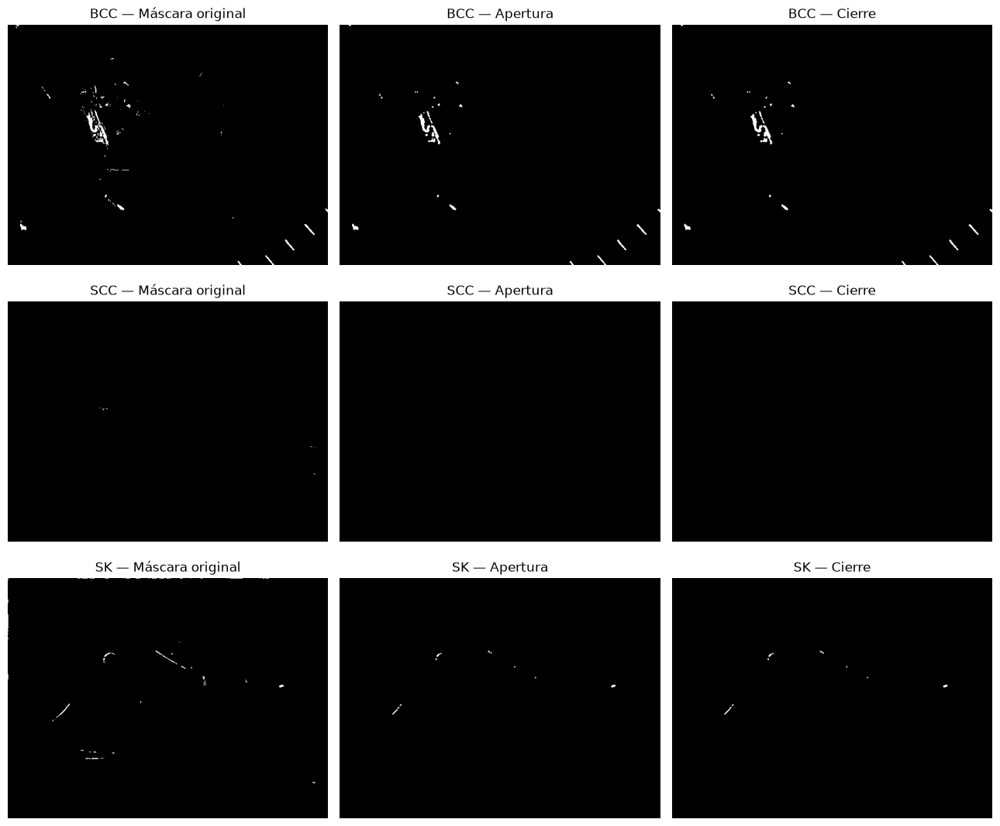

In [69]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

fig, axes = plt.subplots(3, 3, figsize=(13, 11))

for fila, (tipo, mascara) in enumerate(mascaras_artefactos.items()):

    apertura = cv2.morphologyEx(
            mascara, cv2.MORPH_OPEN, kernel
        )
    
    cierre = cv2.morphologyEx(
        apertura, cv2.MORPH_CLOSE, kernel
    )

    variantes = {
        "Máscara original": mascara,
        "Apertura": apertura,
        "Cierre": cierre,
    }

    for columna, (nombre, resultado) in enumerate(variantes.items()):
        axes[fila, columna].imshow(
            resultado, cmap="gray", vmin=0, vmax=255
        )
        axes[fila, columna].set_title(f"{tipo} — {nombre}")
        axes[fila, columna].axis("off")

plt.tight_layout()
plt.show()

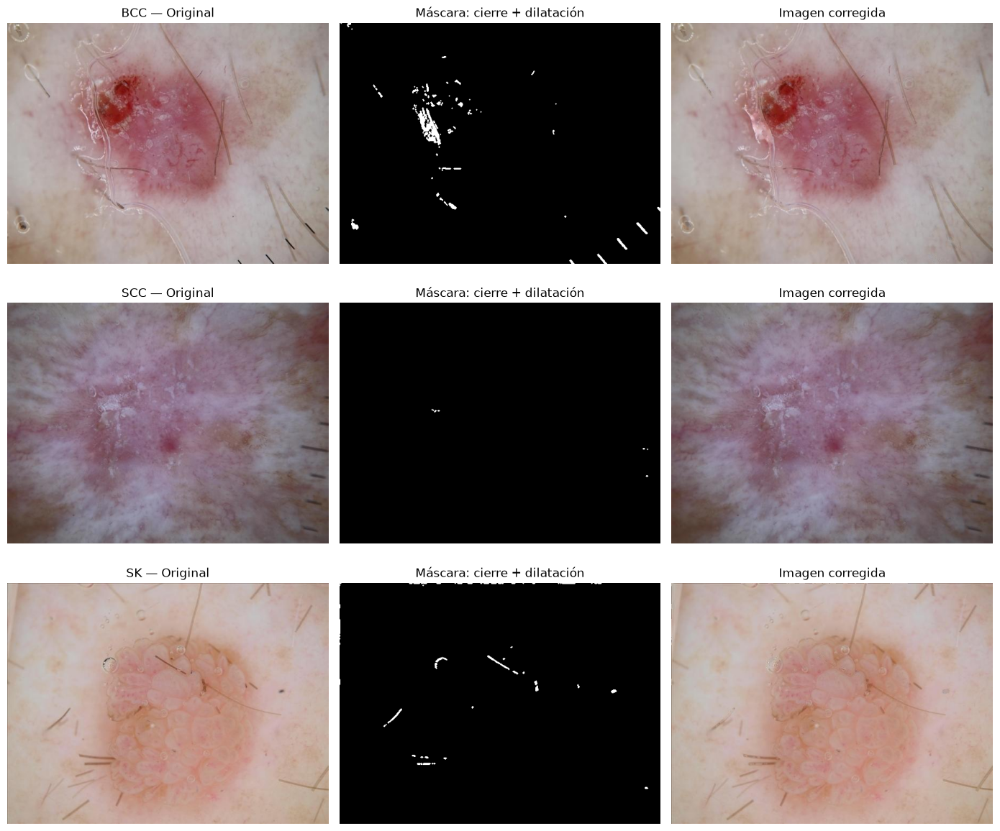

In [70]:
imagenes_corregidas = {}
mascaras_refinadas = {}

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    mascara = mascaras_artefactos[tipo]

    # Unir pequeñas discontinuidades sin eliminar líneas finas
    cierre = cv2.morphologyEx(
        mascara, cv2.MORPH_CLOSE, kernel
    )

    # Ampliar ligeramente la cobertura de los artefactos detectados
    refinada = cv2.dilate(cierre, kernel, iterations=1)

    # Corregir únicamente los píxeles blancos de la máscara
    corregida = cv2.inpaint(
        original, refinada, 3, cv2.INPAINT_TELEA
    )

    mascaras_refinadas[tipo] = refinada
    imagenes_corregidas[tipo] = corregida

    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    axes[fila, 1].imshow(refinada, cmap="gray", vmin=0, vmax=255)
    axes[fila, 1].set_title("Máscara: cierre + dilatación")

    axes[fila, 2].imshow(corregida)
    axes[fila, 2].set_title("Imagen corregida")

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### Resultado de la corrección de artefactos

El cierre seguido de dilatación conserva más estructuras delgadas que
la apertura seguida de cierre. Su aplicación junto con inpainting
atenúa parcialmente pelos y marcas de escala.

Sin embargo, permanecen artefactos sin corregir y se detectan regiones
dentro de la lesión que podrían corresponder a estructuras propias.
Por lo tanto, esta configuración se considera preliminar y no se
asume que preserve todas las características de color y textura.

## Primera prueba de segmentación: efecto de la corrección de artefactos

Se comparan dos alternativas: imagen original e imagen corregida mediante
inpainting. Ambas se convierten a escala de grises y se procesan con
CLAHE utilizando los mismos parámetros.

Luego se aplica Otsu, que determina automáticamente un umbral para cada
imagen. Se utiliza umbralización inversa para representar en blanco las
regiones oscuras consideradas candidatas a lesión.

Esta es una prueba inicial: las regiones oscuras también pueden incluir
pelos, marcas o piel circundante. Se comparan las máscaras y sus contornos
sobre la imagen original para evaluar visualmente sus limitaciones.

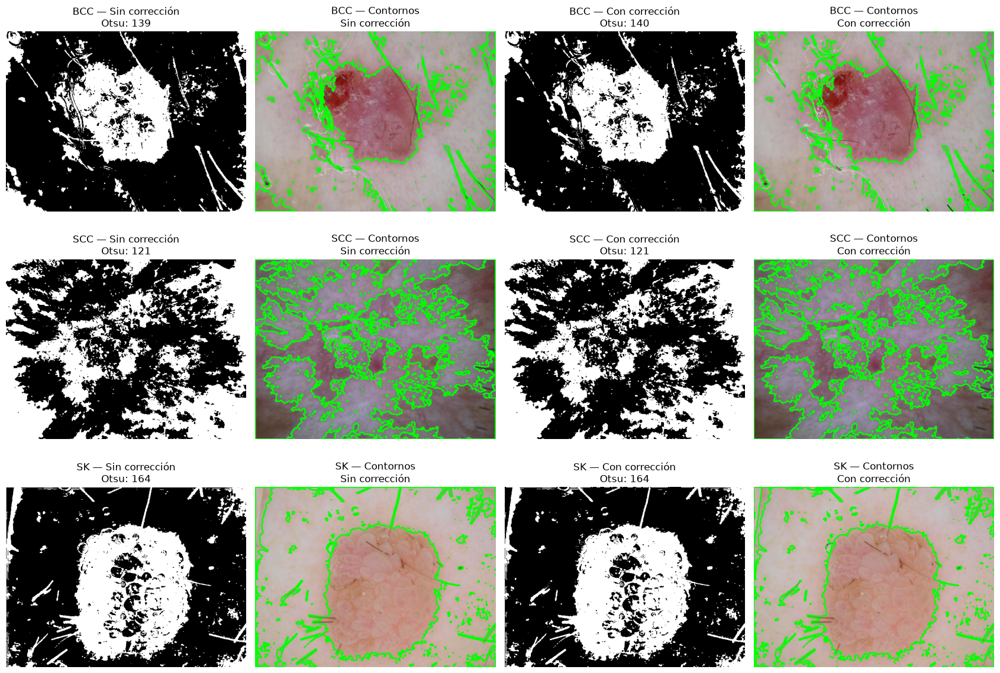

In [71]:
mascaras_otsu = {}

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

fig, axes = plt.subplots(3, 4, figsize=(17, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):

    variantes = {
        "Sin corrección": original,
        "Con corrección": imagenes_corregidas[tipo],
    }

    mascaras_otsu[tipo] = {}

    for columna, (nombre, imagen) in enumerate(variantes.items()):
        gris = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)
        mejorada = clahe.apply(gris)

        umbral, mascara = cv2.threshold(
            mejorada, 0, 255,
            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
        )

        mascaras_otsu[tipo][nombre] = mascara

        # Mostrar máscara
        axes[fila, 2 * columna].imshow(
            mascara, cmap="gray", vmin=0, vmax=255
        )
        axes[fila, 2 * columna].set_title(
            f"{tipo} — {nombre}\nOtsu: {umbral:.0f}"
        )

        # Mostrar contornos sobre la original
        contornos, _ = cv2.findContours(
            mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )

        superpuesta = original.copy()
        cv2.drawContours(
            superpuesta, contornos, -1, (0, 255, 0), 2
        )

        axes[fila, 2 * columna + 1].imshow(superpuesta)
        axes[fila, 2 * columna + 1].set_title(
            f"{tipo} — Contornos\n{nombre}"
        )

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## Segmentación mediante GrabCut

La segmentación mediante Otsu presentó regiones fragmentadas y dificultades
para separar la lesión de la piel circundante. Por ello, se evaluó GrabCut
como método alternativo, que utiliza información de color y relaciones
entre píxeles vecinos para separar primer plano y fondo.

Se definió un rectángulo inicial excluyendo un margen del 5 % de la imagen,
considerado fondo, y se aplicaron cinco iteraciones. Se utilizaron los
mismos parámetros para los tres diagnósticos.

Las máscaras obtenidas presentaron regiones más continuas que las de Otsu,
aunque persistió la inclusión de piel circundante y algunos artefactos.
Como refinamiento, se conservó el componente conectado de mayor área,
suponiendo que corresponde a la lesión principal, para eliminar pequeñas
regiones aisladas.

Finalmente, se visualizaron los contornos sobre las imágenes originales
para inspeccionar la delimitación. Esta comparación es cualitativa y no
demuestra por sí sola una mayor precisión de segmentación.

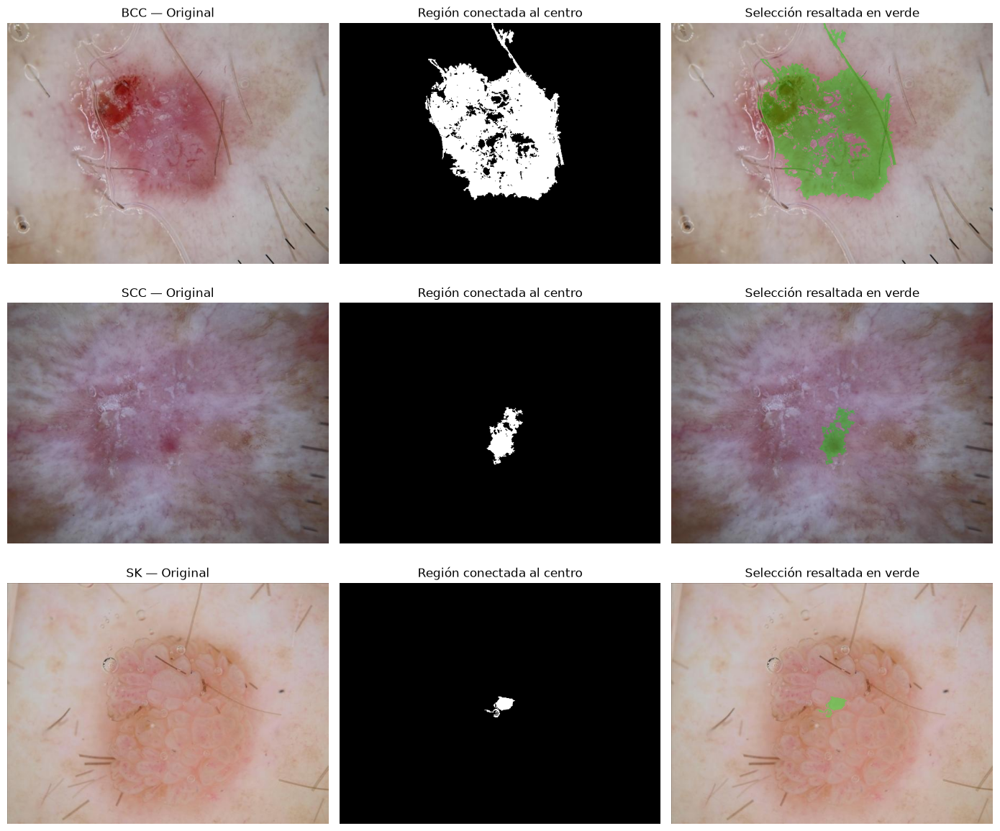

In [72]:
mascaras_lesion = {}

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    mascara = mascaras_otsu[tipo]["Con corrección"]
    alto, ancho = mascara.shape

    # Considerar candidata la clase presente en el centro:
    # puede ser blanca o negra en la máscara de Otsu
    valor_central = mascara[alto // 2, ancho // 2]
    candidata = (mascara == valor_central).astype("uint8")

    # Conservar solamente la región conectada al centro
    _, etiquetas = cv2.connectedComponents(candidata, connectivity=8)
    etiqueta_central = etiquetas[alto // 2, ancho // 2]

    seleccion = (
        (etiquetas == etiqueta_central).astype("uint8") * 255
    )

    mascaras_lesion[tipo] = seleccion

    # Resaltar los píxeles seleccionados sobre la original
    superpuesta = original.copy()
    dentro = seleccion > 0
    superpuesta[dentro] = (
        0.65 * original[dentro] + 0.35 * np.array([0, 255, 0])
    ).astype("uint8")

    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    axes[fila, 1].imshow(
        seleccion, cmap="gray", vmin=0, vmax=255
    )
    axes[fila, 1].set_title("Región conectada al centro")

    axes[fila, 2].imshow(superpuesta)
    axes[fila, 2].set_title("Selección resaltada en verde")

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

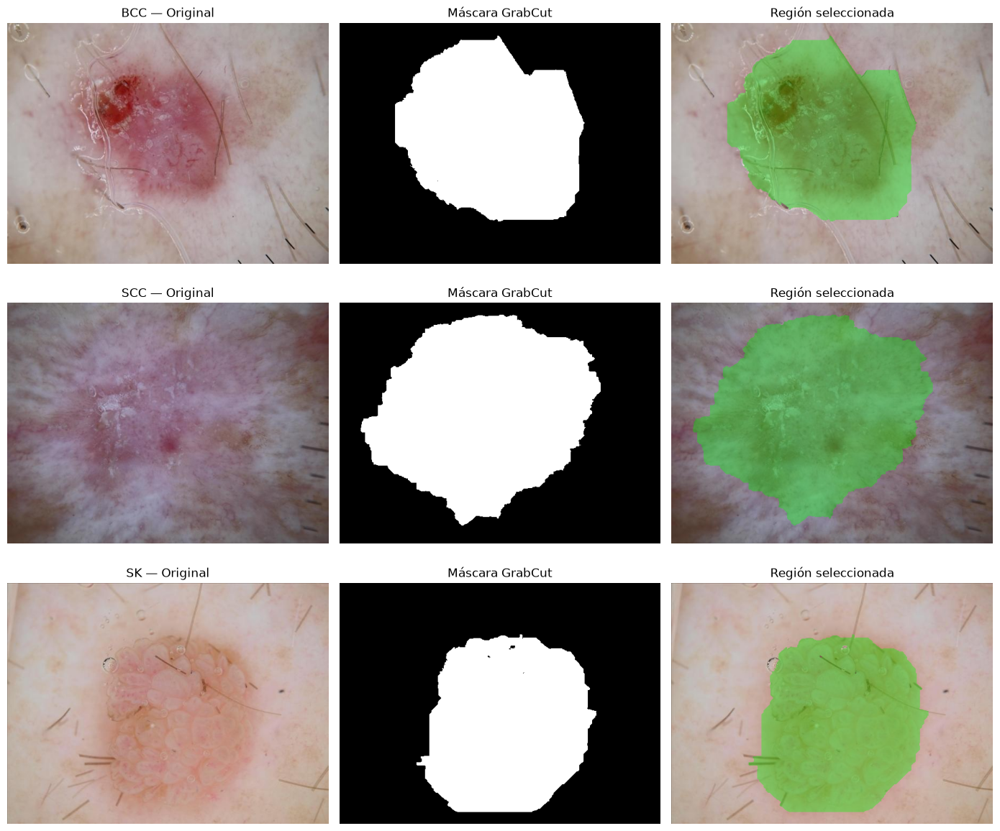

In [73]:
mascaras_grabcut = {}

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    alto, ancho = original.shape[:2]

    # Rectángulo inicial: excluye un margen del 5 %
    mx = max(1, int(ancho * 0.05))
    my = max(1, int(alto * 0.05))
    rectangulo = (mx, my, ancho - 2 * mx, alto - 2 * my)

    etiquetas = np.zeros((alto, ancho), dtype=np.uint8)
    modelo_fondo = np.zeros((1, 65), dtype=np.float64)
    modelo_lesion = np.zeros((1, 65), dtype=np.float64)

    cv2.setRNGSeed(42)
    cv2.grabCut(
        original, etiquetas, rectangulo,
        modelo_fondo, modelo_lesion,
        5, cv2.GC_INIT_WITH_RECT
    )

    # Primer plano seguro o probable
    mascara = np.where(
        (etiquetas == cv2.GC_FGD) |
        (etiquetas == cv2.GC_PR_FGD),
        255, 0
    ).astype("uint8")

    mascaras_grabcut[tipo] = mascara

    superpuesta = original.copy()
    dentro = mascara > 0
    superpuesta[dentro] = (
        0.65 * original[dentro] +
        0.35 * np.array([0, 255, 0])
    ).astype("uint8")

    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    axes[fila, 1].imshow(
        mascara, cmap="gray", vmin=0, vmax=255
    )
    axes[fila, 1].set_title("Máscara GrabCut")

    axes[fila, 2].imshow(superpuesta)
    axes[fila, 2].set_title("Región seleccionada")

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

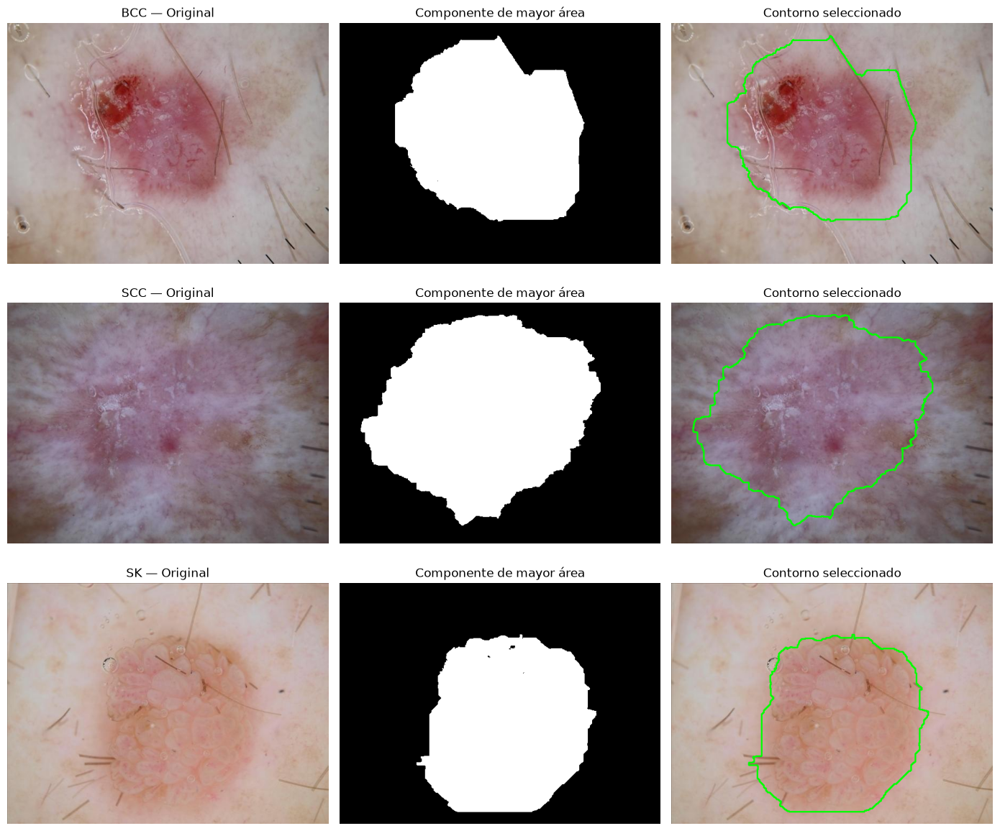

In [74]:
mascaras_limpias = {}

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for fila, (tipo, original) in enumerate(imagenes.items()):
    mascara = mascaras_grabcut[tipo]

    # Identificar las regiones blancas conectadas
    cantidad, etiquetas, estadisticas, _ = (
        cv2.connectedComponentsWithStats(mascara, connectivity=8)
    )

    limpia = np.zeros_like(mascara)

    if cantidad > 1:
        # La etiqueta 0 es el fondo
        mayor = 1 + np.argmax(
            estadisticas[1:, cv2.CC_STAT_AREA]
        )
        limpia[etiquetas == mayor] = 255

    mascaras_limpias[tipo] = limpia

    # Dibujar solamente el contorno de la región seleccionada
    contornos, _ = cv2.findContours(
        limpia, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    resultado = original.copy()
    cv2.drawContours(resultado, contornos, -1, (0, 255, 0), 2)

    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"{tipo} — Original")

    axes[fila, 1].imshow(
        limpia, cmap="gray", vmin=0, vmax=255
    )
    axes[fila, 1].set_title("Componente de mayor área")

    axes[fila, 2].imshow(resultado)
    axes[fila, 2].set_title("Contorno seleccionado")

    for ax in axes[fila]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [78]:
%matplotlib inline